# Breast Cancer Wisconsin (Diagnostic)

**Student ID: 202552200002**  
**Name: Hamza El Massaoudy**

Fully executed CESS breast cancer assessment notebook.

This notebook uses the Wisconsin Diagnostic dataset bundled with scikit-learn.
Its 569 feature rows and diagnosis labels were verified against the supplied
`breastData.csv`. No separate CSV file or computer-specific path is required.
There are 30 input features. Benign is encoded as 0 and malignant as 1.

The scaler is fitted on training data and reused on test data. Confusion matrices
include both counts and correct row-normalized proportions.

## Importing Needed Libraries

In [1]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix

# **Loading Data**

In [2]:
from sklearn.datasets import load_breast_cancer

wisconsin = load_breast_cancer()
feature_columns = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
df = pd.DataFrame(wisconsin.data, columns=feature_columns)
df.insert(0, 'diagnosis', np.where(wisconsin.target == 0, 'M', 'B'))
print('Wisconsin Diagnostic dataset:', df.shape[0], 'records and', len(feature_columns), 'features')

Wisconsin Diagnostic dataset: 569 records and 30 features


In [3]:
df.head(10)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [4]:
df.shape

(569, 31)

# **Cleaning & Analysis**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [6]:
df.isna().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [7]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [8]:
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})

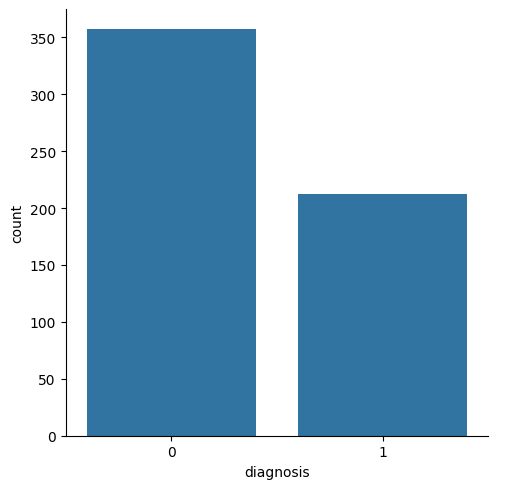

In [9]:
sns.catplot(x='diagnosis', data=df, kind='count')

In [10]:
# Ignore identifier/empty CSV columns if present; the bundled data excludes them.
df.drop(columns=['id', 'Unnamed: 32'], errors='ignore', inplace=True)

In [11]:
df.head(10)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,1,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,1,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,1,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,1,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,1,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.000000,0.000000,0.000000,1.000000,1.00000
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400


In [13]:
# sns.pairplot(df, hue='diagnosis')

In [14]:
df['diagnosis'] = df['diagnosis'].astype(float)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    float64
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [16]:
correlation = df.corr()

<Axes: >

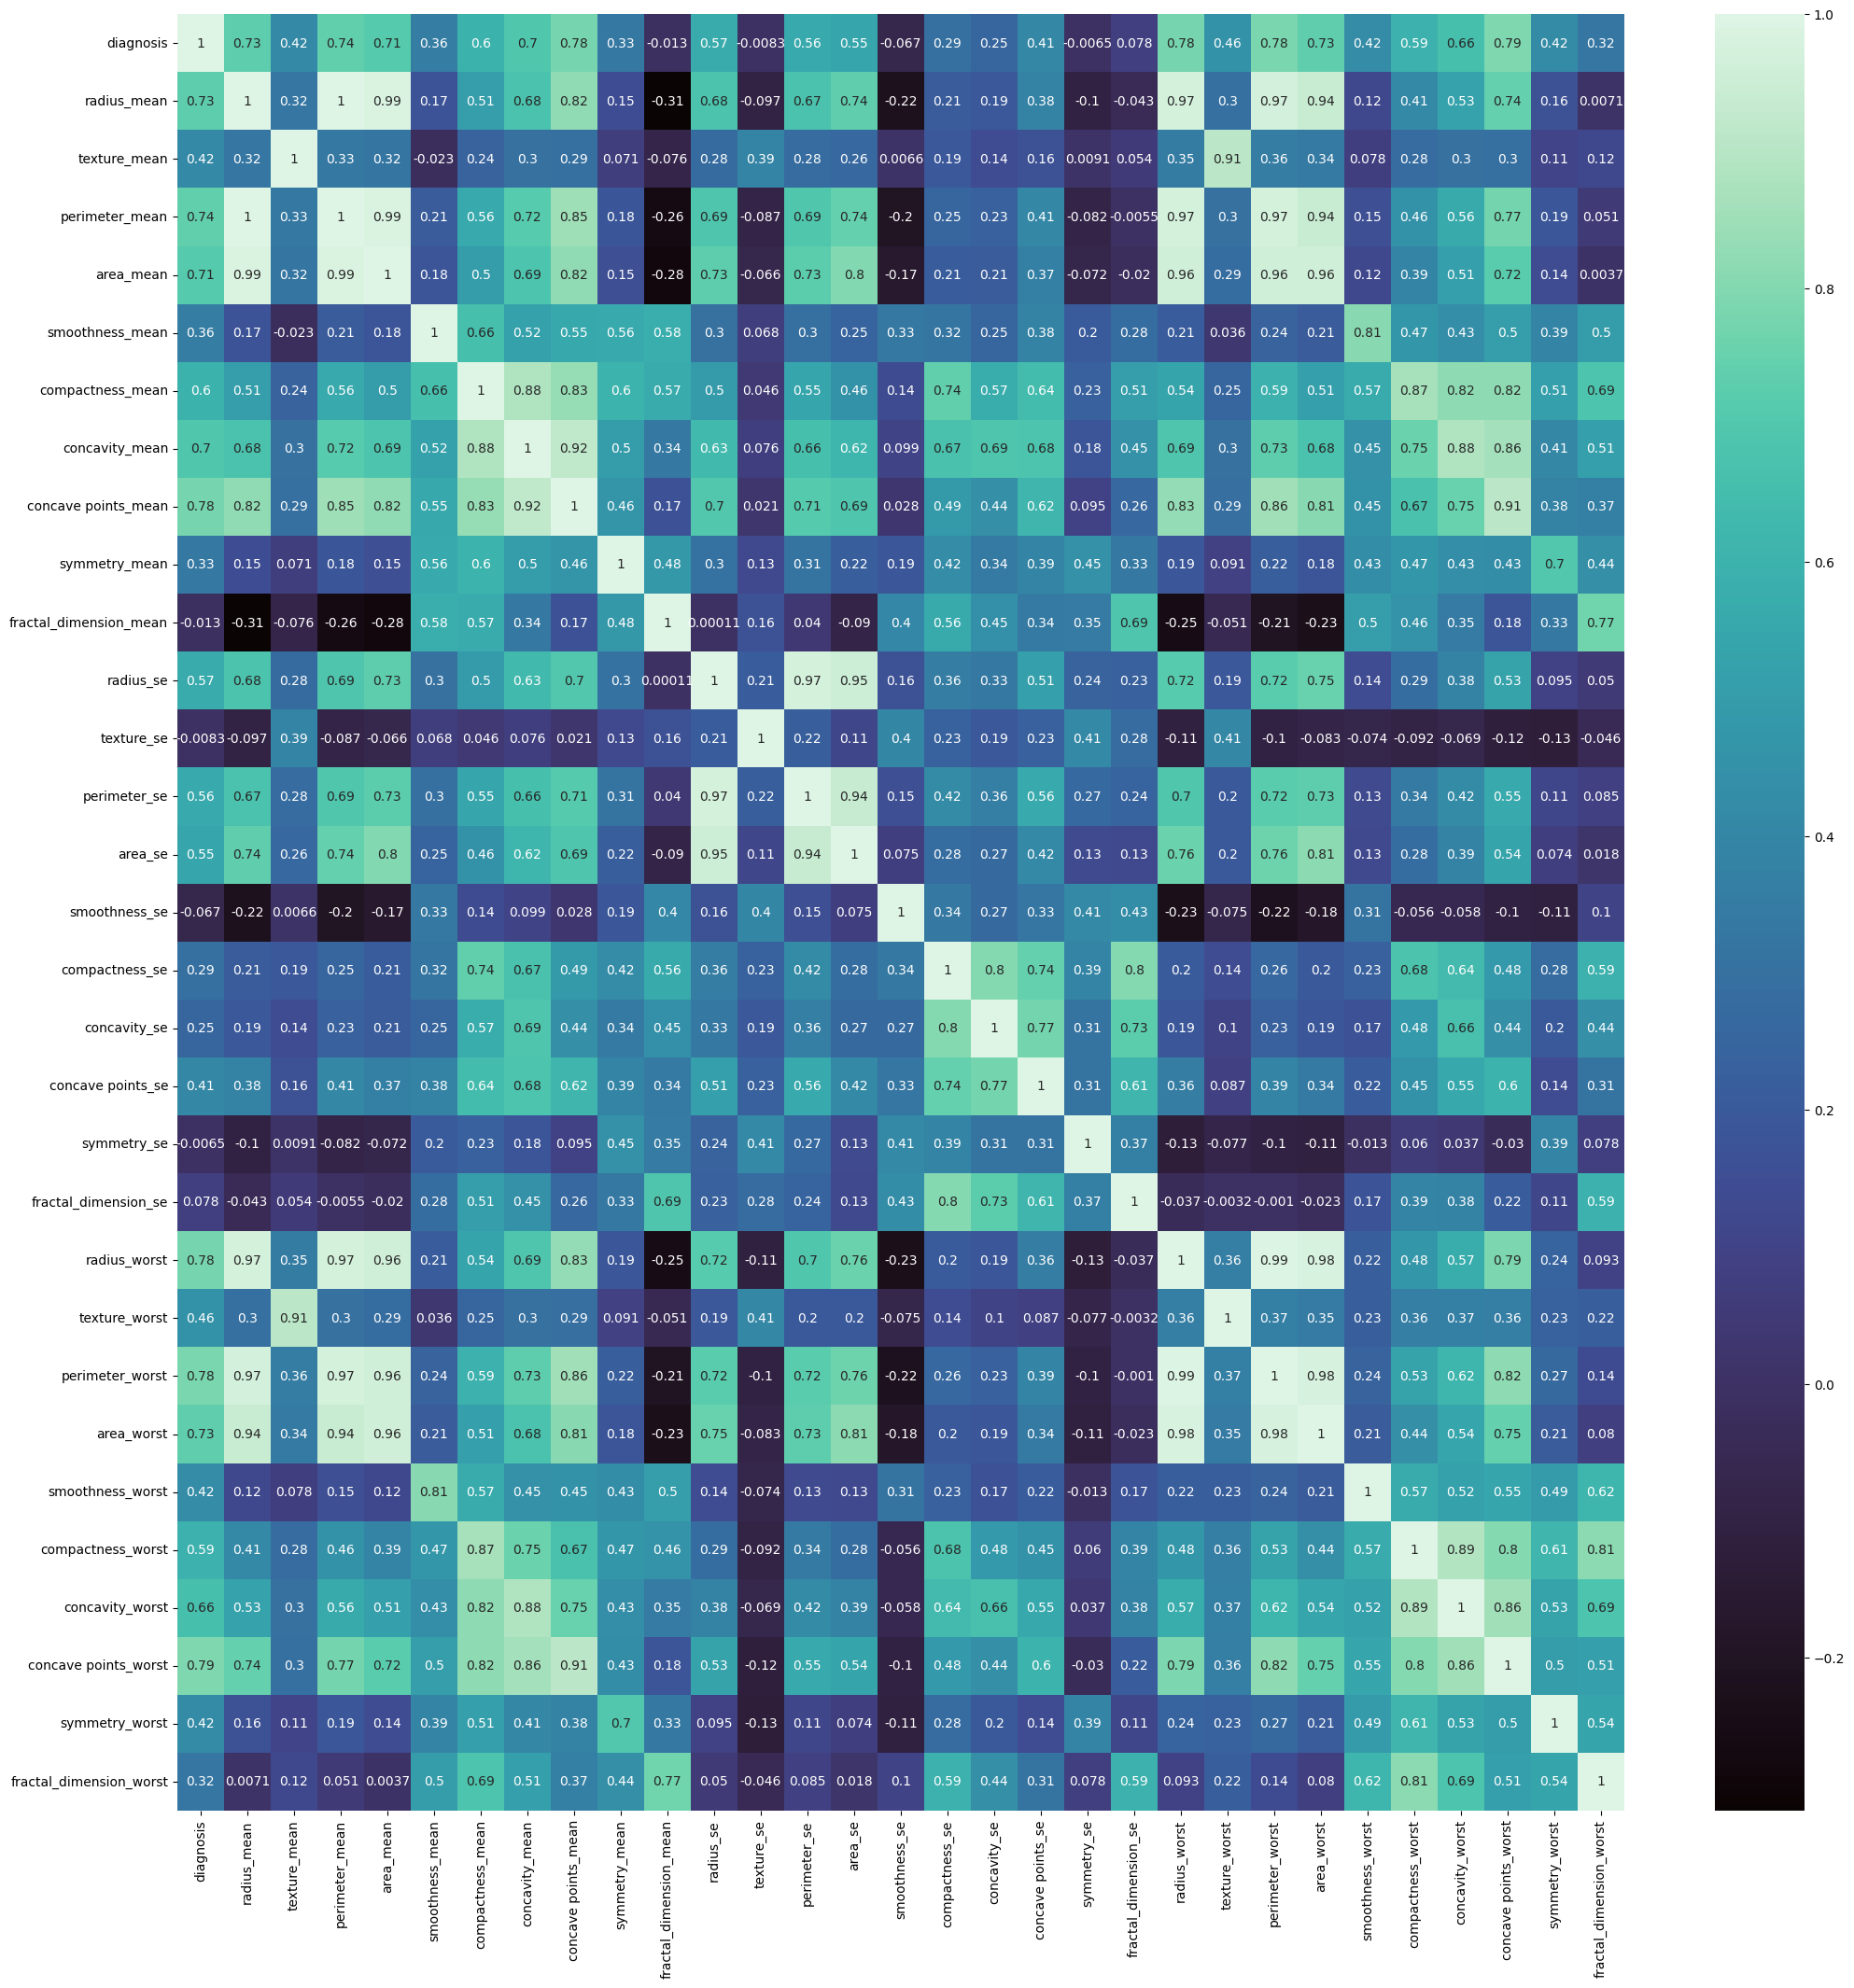

In [17]:
plt.figure(figsize=(25,25))
sns.heatmap(correlation, annot=True, cmap='mako')

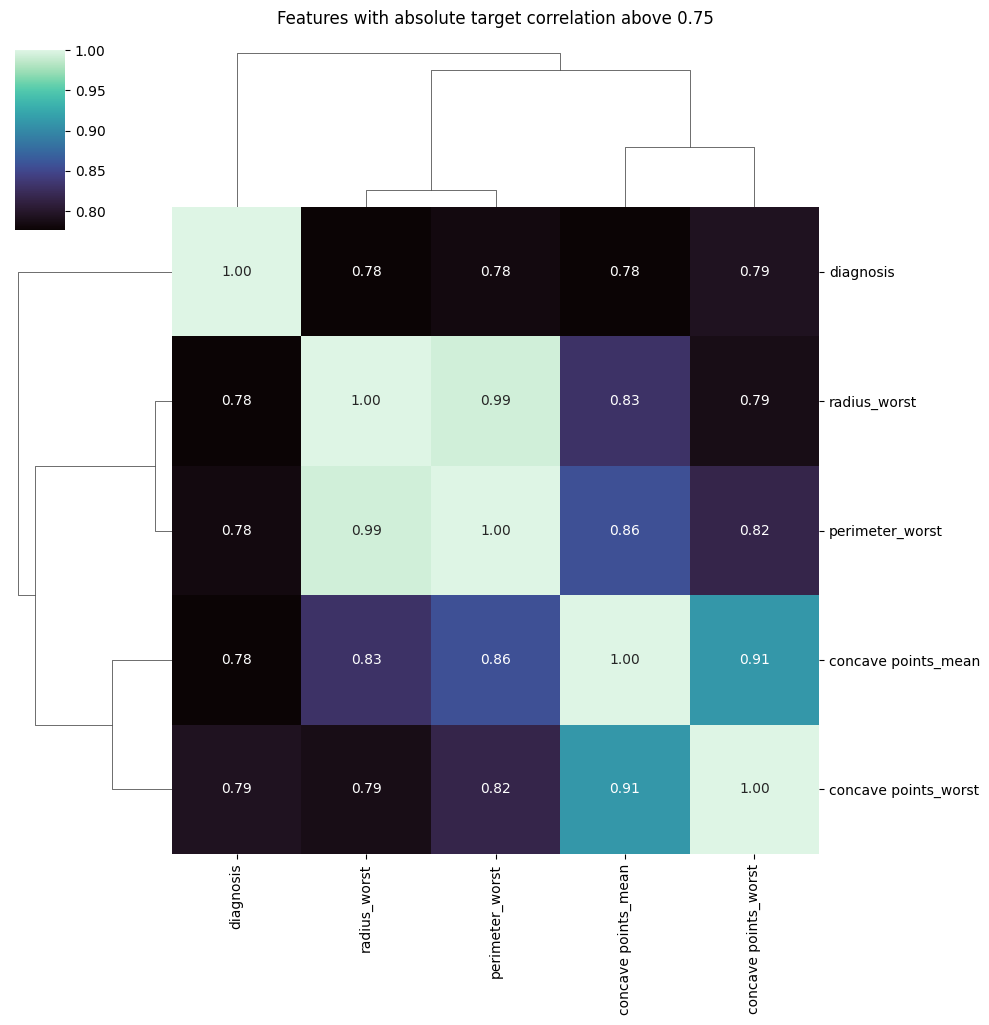

In [18]:
threshold = 0.75
feature_mask = correlation['diagnosis'].abs() > threshold
correlation_features = correlation.columns[feature_mask].tolist()
cluster = sns.clustermap(df[correlation_features].corr(), annot=True, fmt='.2f', cmap='mako')
cluster.fig.suptitle('Features with absolute target correlation above 0.75', y=1.02)
plt.show()

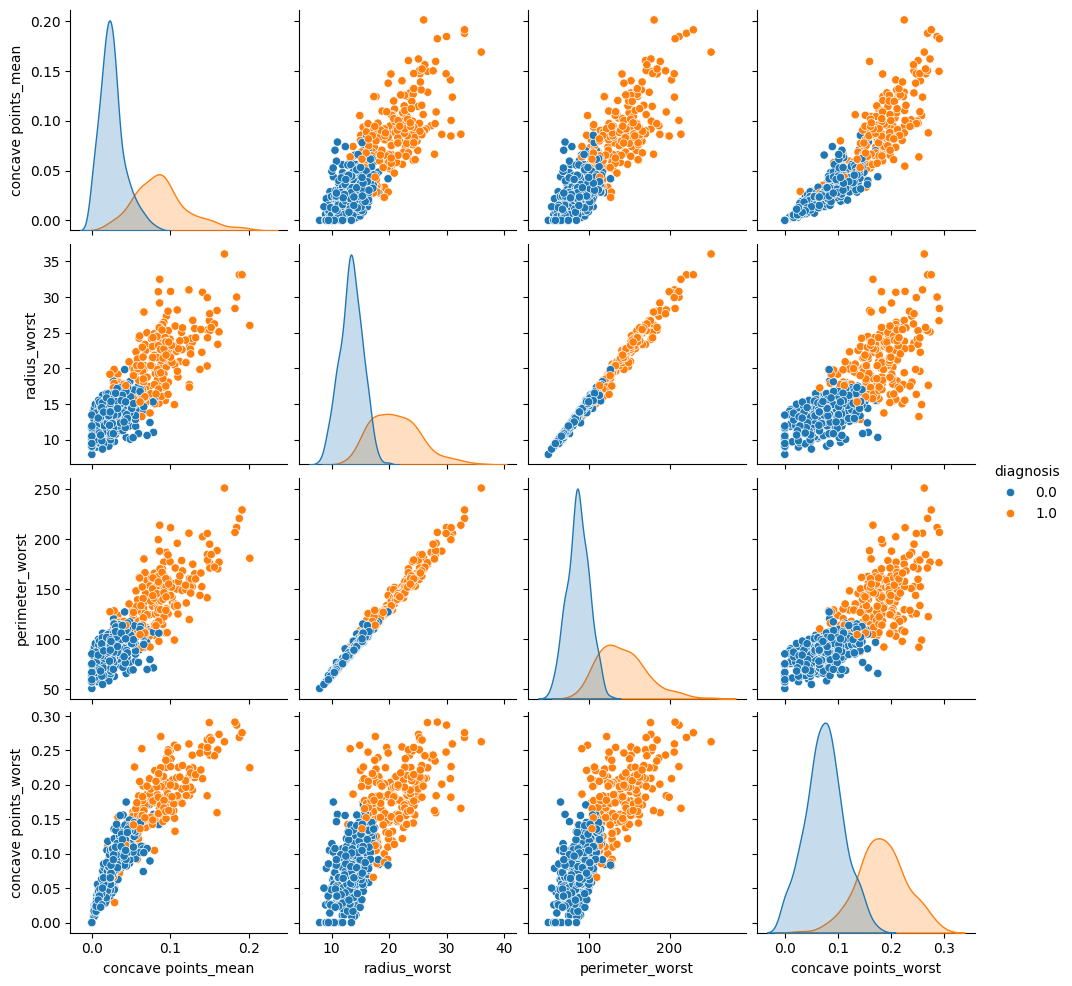

In [19]:
sns.pairplot(df[correlation_features], diag_kind = "kde",  hue="diagnosis")
plt.show()

# **Model**

In [20]:
X = df.drop(['diagnosis'], axis=1)
y = df['diagnosis']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
s = StandardScaler()
X_train = s.fit_transform(X_train)
X_test = s.transform(X_test)

In [23]:
Algorithm = ['RandomForestClassifier','DecisionTreeClassifier','KNeighborsClassifier','LogisticRegression','Naive Bayes']
Accuracy=[]

In [24]:
def algorithm(model):
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)

    cm = confusion_matrix(y_test, prediction, labels=[0, 1])
    group_names = ['True Negative', 'False Positive', 'False Negative', 'True Positive']
    annotations = [f'{name}\n{count}\n{count / cm.sum():.2%}'
                   for name, count in zip(group_names, cm.flatten())]
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=np.asarray(annotations).reshape(2, 2), fmt='', cmap='Blues',
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.title(type(model).__name__ + ' — Confusion Matrix')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.tight_layout()
    plt.show()

    normalized_cm = confusion_matrix(y_test, prediction, labels=[0, 1], normalize='true')
    plt.figure(figsize=(7, 5))
    sns.heatmap(normalized_cm, annot=True, fmt='.1%', cmap='Blues', vmin=0, vmax=1,
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.title(type(model).__name__ + ' — Row-normalized Confusion Matrix')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.tight_layout()
    plt.show()

    print(cm)
    print(classification_report(y_test, prediction, labels=[0, 1],
                                target_names=['Benign', 'Malignant']))
    print('Test accuracy:', f'{accuracy:.2%}')
    Accuracy.append(accuracy * 100)

**Random Forest Classification**

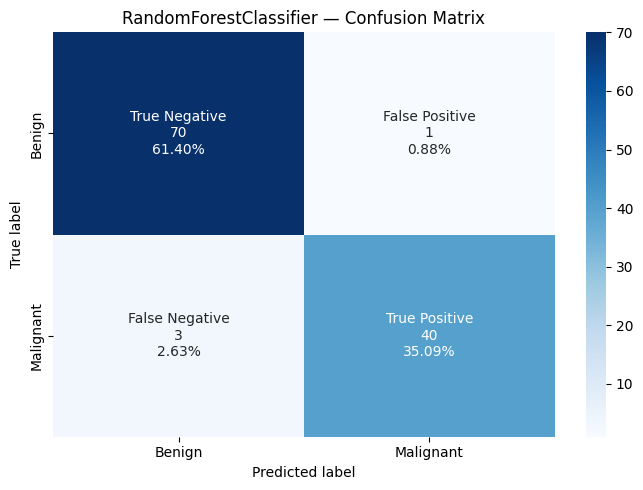

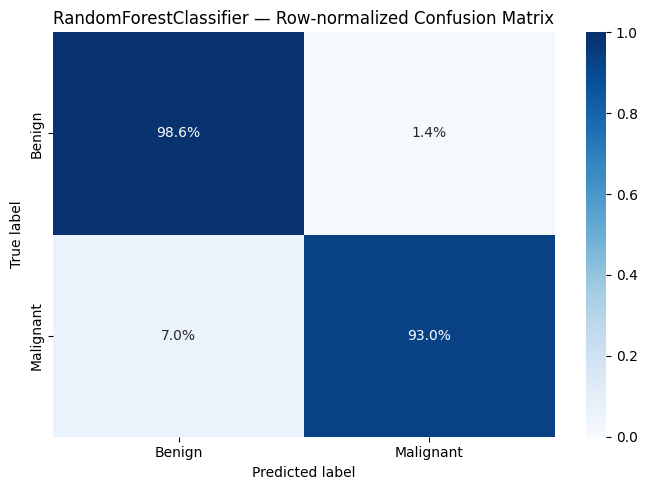

[[70  1]
 [ 3 40]]
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        71
   Malignant       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Test accuracy: 96.49%


In [25]:
model_1 = RandomForestClassifier(n_estimators=100, random_state=42)
algorithm(model_1)

**Decision Tree**

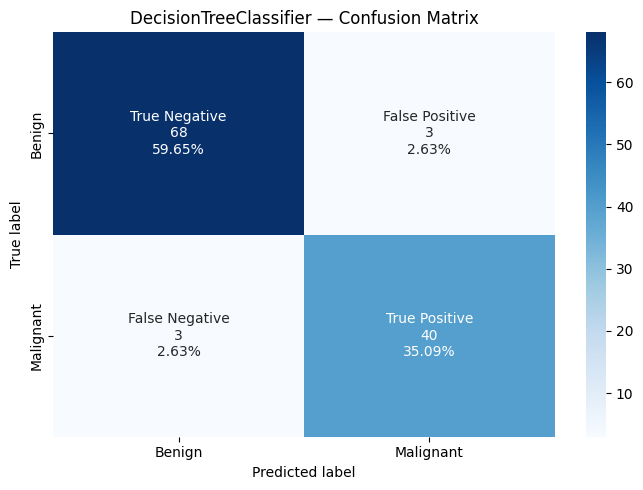

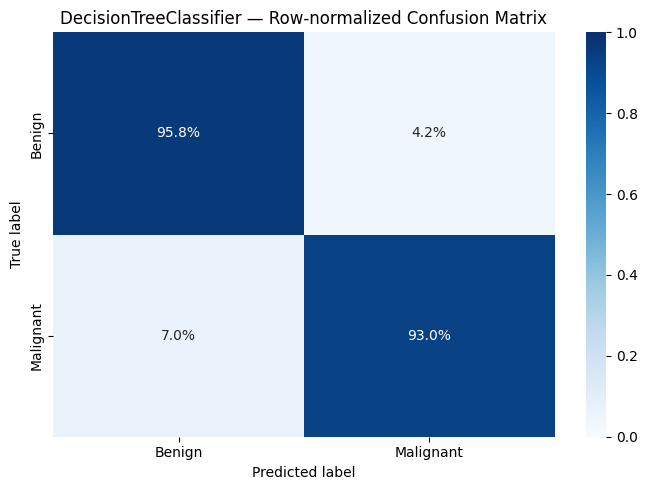

[[68  3]
 [ 3 40]]
              precision    recall  f1-score   support

      Benign       0.96      0.96      0.96        71
   Malignant       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Test accuracy: 94.74%


In [26]:
model_2 = DecisionTreeClassifier(random_state=42)
algorithm(model_2)

**K Nearest Neighbor**

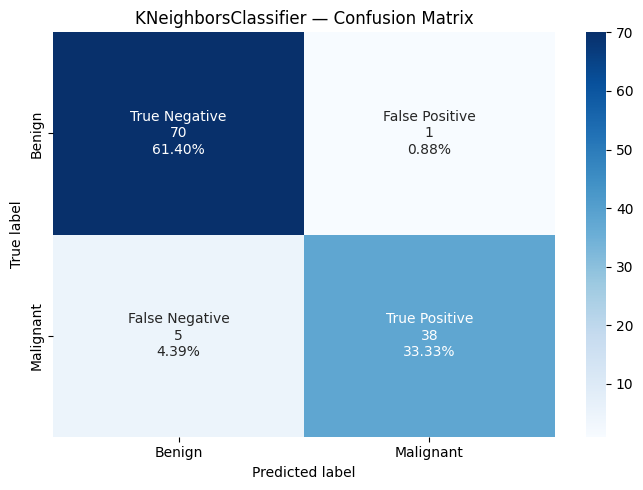

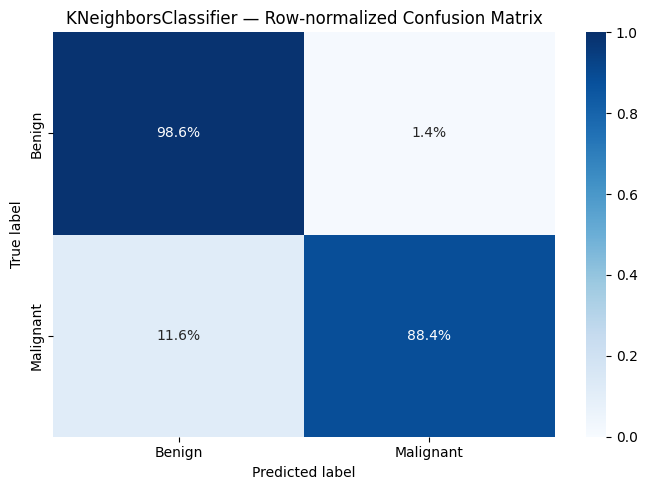

[[70  1]
 [ 5 38]]
              precision    recall  f1-score   support

      Benign       0.93      0.99      0.96        71
   Malignant       0.97      0.88      0.93        43

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

Test accuracy: 94.74%


In [27]:
model_3 = KNeighborsClassifier(n_neighbors=2)
algorithm(model_3)

**Logistic Regression**

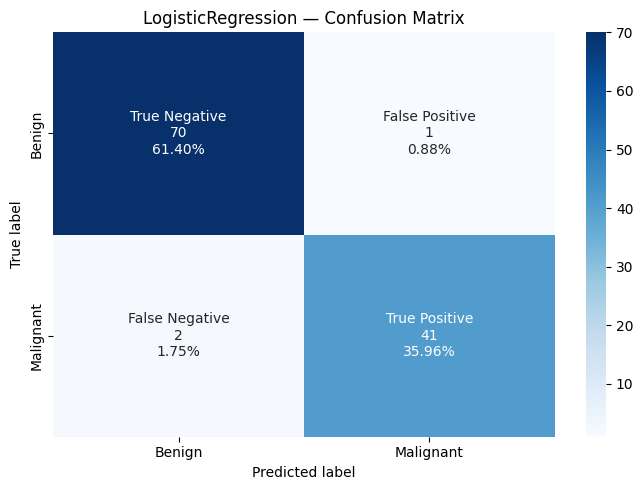

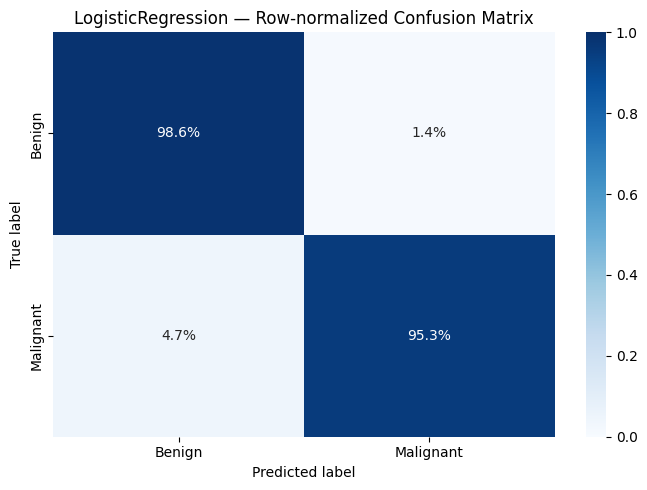

[[70  1]
 [ 2 41]]
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        71
   Malignant       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Test accuracy: 97.37%


In [28]:
model_4 = LogisticRegression(max_iter=1000)
algorithm(model_4)

**Naive Bayes**

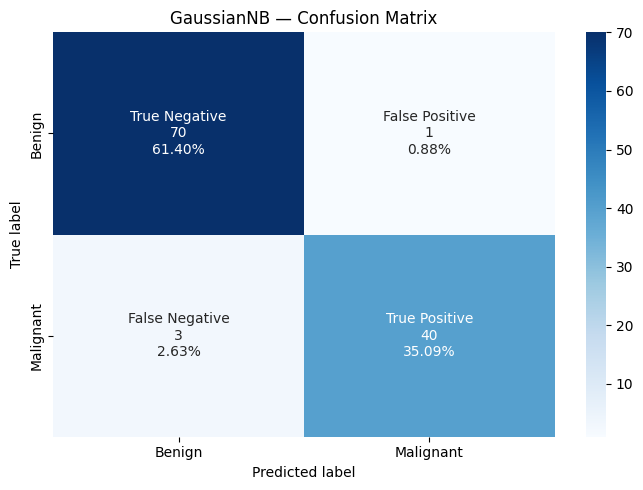

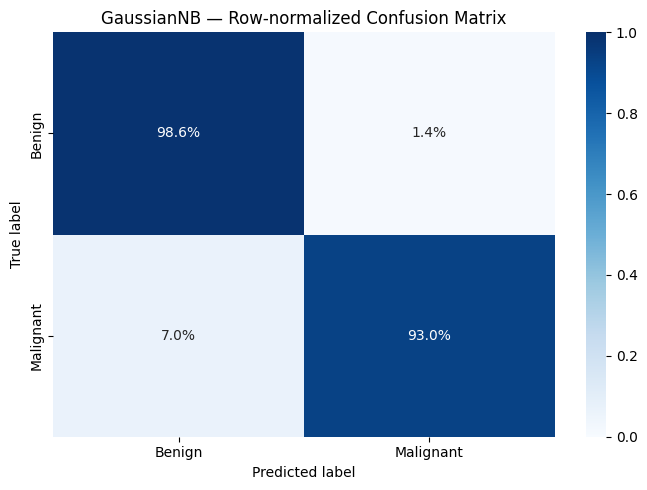

[[70  1]
 [ 3 40]]
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        71
   Malignant       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Test accuracy: 96.49%


In [29]:
model_5 = GaussianNB()
algorithm(model_5)

In [30]:
print(Accuracy)

[96.49122807017544, 94.73684210526315, 94.73684210526315, 97.36842105263158, 96.49122807017544]


In [31]:
score = pd.DataFrame({'Algorithm':Algorithm,'Accuracy':Accuracy })
score

,Algorithm,Accuracy
0,RandomForestClassifier,96.491228
1,DecisionTreeClassifier,94.736842
2,KNeighborsClassifier,94.736842
3,LogisticRegression,97.368421
4,Naive Bayes,96.491228


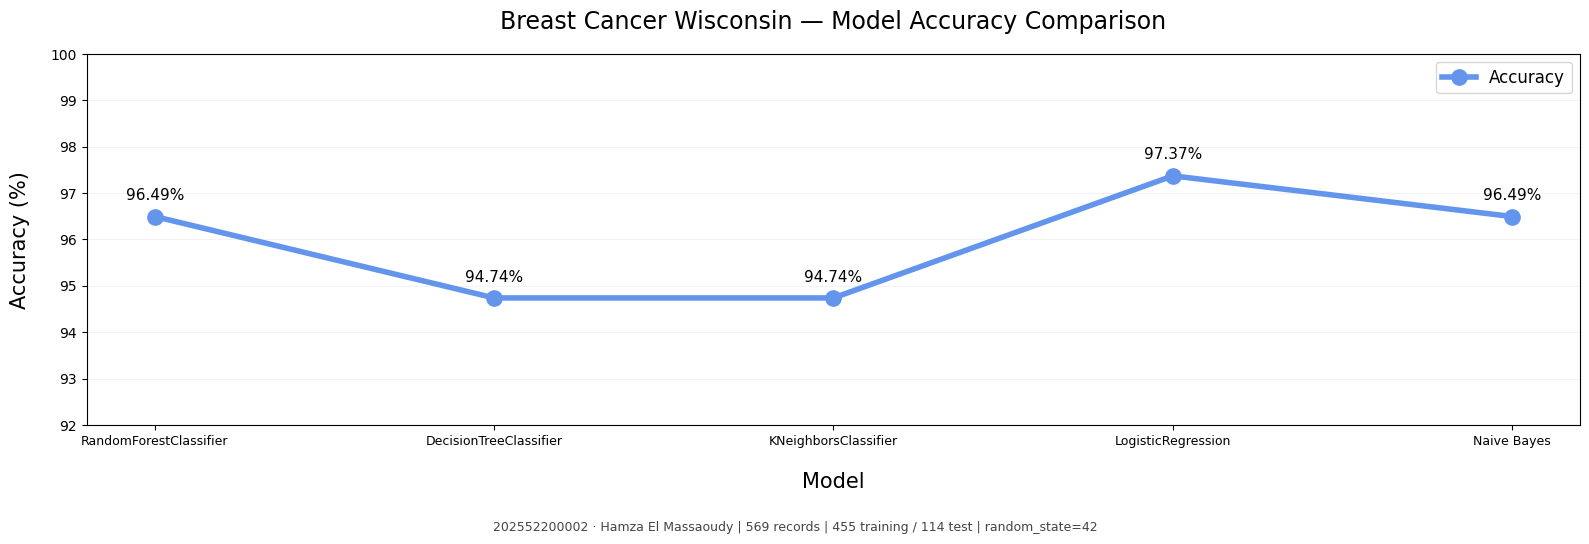

             Algorithm  Accuracy
RandomForestClassifier 96.491228
DecisionTreeClassifier 94.736842
  KNeighborsClassifier 94.736842
    LogisticRegression 97.368421
           Naive Bayes 96.491228


In [32]:
# Accuracy comparison for all five models on the same held-out split.
with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(16, 5.5))
    ax.plot(score.Algorithm, score.Accuracy, label='Accuracy', lw=4,
            color='CornflowerBlue', marker='o', markersize=11)
    for position, value in enumerate(score.Accuracy):
        ax.annotate(f'{value:.2f}%', (position, value), xytext=(0, 12),
                    textcoords='offset points', ha='center', fontsize=11)
    ax.legend(fontsize=12, loc='upper right')
    ax.set_xlabel('Model', fontsize=15, labelpad=17)
    ax.set_ylabel('Accuracy (%)', fontsize=15, labelpad=15)
    ax.set_title('Breast Cancer Wisconsin — Model Accuracy Comparison', fontsize=17, pad=18)
    ax.set_ylim(92, 100)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='y', alpha=0.15)
    fig.text(0.5, 0.025,
             f'202552200002 · Hamza El Massaoudy | {len(df)} records | {len(y_train)} training / {len(y_test)} test | random_state=42',
             ha='center', fontsize=9, color='#444444')
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()
print(score.to_string(index=False))